<div style="border: solid green 2px; padding: 20px">

  <b>Overall Summary of the Project – Iteration 2</b><br><br>
  Hello Obed, congratulations on submitting your project!<br><br>

  My name is <b>Victor Camargo</b> 
  (<a href="https://hub.tripleten.com/u/834cb557" target="_blank">TripleTen Hub profile</a>) and I’ll be reviewing your project today.<br><br>

  <b>What you did well:</b><br>
  ✅ You correctly recalculated the rougher recovery and verified it with a near-zero MAE, demonstrating careful validation of a key calculated feature.<br>
  ✅ You completed the full end-to-end pipeline, including data preparation, exploratory analysis, model training, and final evaluation using the correct sMAPE formulation.<br>
  ✅ The modeling approach is sound and the final test evaluation shows reasonable generalization performance on unseen data.<br><br>

  <b>Suggestions for future improvement (optional):</b><br>
  ⚠️ When reporting evaluation results, consider explicitly printing the number of valid samples used after filtering missing targets to improve interpretability.<br>
  ⚠️ You could further strengthen the modeling section by adding hyperparameter tuning and briefly justifying the final model choice based on tuned cross-validated performance.<br><br>

  <b>Project Status:</b><br>
  <div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
    <b>Approved ✅</b>
  </div>

</div>


<div style="border:solid green 2px; padding: 20px">

**Hello Obed,**

My name is **John Dickson** (https://hub.tripleten.com/u/13efa053) and today I'll be reviewing your project!

You’ll find specific notes inside the project file, marked green, yellow or red.


**Note:** Please do not remove or change my comments - they will help me in the future reviews and will make the process smoother for both of us. 

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment</b> 
    
Such comment will mark efficient solutions and good ideas that can be used in other projects. It will also point at the document formatting, comments, and analysis. 
</div>

<div class="alert alert-warning"; style="border-left: 7px solid gold">
<b>⚠️ Reviewer's comment</b> 
    
The parts marked with yellow comments indicate that there is room for optimisation. Though the correction is not necessary it is good if you implement it.
</div>

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment</b> 
    
If you see such a comment, it means that there is a problem that needs to be fixed. Please note that I won't be able to accept your project until the issue is resolved.
</div>

---
    
You are also welcome to leave your own comments, explain any changes you've made, or ask questions by marking them with a different color. You can use the example below (copy the code and use it in a Markdown-type cell):

```
    
<div class="alert alert-info"; style="border-left: 7px solid blue">
<b>Student’s Comment</b>

```
    
It will appear like this:
    
<div class="alert alert-info"; style="border-left: 7px solid blue">
<b>Student’s Comment</b></div>

<hr>
    
📌 Please feel free to schedule a 1:1 sessions with our tutors, join daily coworking sessions, or ask questions on TripleTen Hub if you need assistance 😉 
</div>

<div style="border:solid Purple 2px; padding: 20px">

V1

<div style="border: 2px solid Green; padding: 5px; margin: 5px">
 
**What Was Great:**

- MAE Caclulation is good.
- Identified missing columns and their type.
- Appropriate preprocessing.
- Using KDE for particle size distribution is appropriate
</div>
<div style="border: 2px solid red; padding: 5px; margin: 5px">

**What could be improved:**

- Missing basic data exploration
- Some missing stages for some graphs.
- Check sMAPE formula matches what was given
- Different models not trained, no model tuning present.
- There is an error in the final code cell that prevents it from running.
</div>

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, train_test_split, KFold
from sklearn.metrics import mean_absolute_error, make_scorer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import SimpleImputer

In [2]:
# Load the datasets
train = pd.read_csv('/datasets/gold_recovery_train.csv')
test = pd.read_csv('/datasets/gold_recovery_test.csv')
full = pd.read_csv('/datasets/gold_recovery_full.csv')

In [3]:

# Convert date column to datetime and set index
for df in [train, test, full]:
    df['date'] = pd.to_datetime(df['date'])
    df.set_index('date', inplace=True)
train.shape, test.shape, full.shape

((16860, 86), (5856, 52), (22716, 86))

In [4]:
# Check all three datasets
print("Training data:")
train.info()
print("\nTest data:")
test.info()
print("\nFull data:")
full.info()

Training data:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 16860 entries, 2016-01-15 00:00:00 to 2018-08-18 10:59:59
Data columns (total 86 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   final.output.concentrate_ag                         16788 non-null  float64
 1   final.output.concentrate_pb                         16788 non-null  float64
 2   final.output.concentrate_sol                        16490 non-null  float64
 3   final.output.concentrate_au                         16789 non-null  float64
 4   final.output.recovery                               15339 non-null  float64
 5   final.output.tail_ag                                16794 non-null  float64
 6   final.output.tail_pb                                16677 non-null  float64
 7   final.output.tail_sol                               16715 non-null  float64
 8   final.output.tail_au      

In [5]:
display(df.isnull().sum())

final.output.concentrate_ag                     89
final.output.concentrate_pb                     87
final.output.concentrate_sol                   385
final.output.concentrate_au                     86
final.output.recovery                         1963
                                              ... 
secondary_cleaner.state.floatbank5_a_level     101
secondary_cleaner.state.floatbank5_b_air       101
secondary_cleaner.state.floatbank5_b_level     100
secondary_cleaner.state.floatbank6_a_air       119
secondary_cleaner.state.floatbank6_a_level     101
Length: 86, dtype: int64

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`1.1` We are missing even basic data checks.
</div>

In [6]:
# Calculate recovery using the formula
recovery_calc_code =""
# C = rougher.output.concentrate_au
# F = rougher.input.feed_au
# T = rougher.output.tail_au

def calculate_recovery(C, F, T):
    return (C * (F - T)) / (F * (C - T)) * 100

# Apply on training data
true = train['rougher.output.recovery']
C = train['rougher.output.concentrate_au']
F = train['rougher.input.feed_au']
T = train['rougher.output.tail_au']
calculated = calculate_recovery(C, F, T)

# Drop NaNs to compare
mask = ~true.isna() & ~calculated.isna()
mae = mean_absolute_error(true[mask], calculated[mask])
mae

9.303415616264301e-15

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V1</b> 
    
`1.2` Calculation looks correct.
</div>

In [7]:
# Define the column variables
columns_in_train = train.columns
columns_in_test = test.columns

print('The number of features in the training set is', len(columns_in_train))
print('The number of features in the test set is', len(columns_in_test))

difference = train.columns.difference(test.columns)
print('The column count difference between the training and test set is', len(difference))
print()

The number of features in the training set is 86
The number of features in the test set is 52
The column count difference between the training and test set is 34



Recovery Calculation Check

We manually computed the `rougher.output.recovery` using the provided formula:
\[
\text{Recovery} = \frac{C \cdot (F - T)}{F \cdot (C - T)} \times 100
\]
Where:
- **C** = `rougher.output.concentrate_au`
- **F** = `rougher.input.feed_au`  
- **T** = `rougher.output.tail_au`
We then calculated the **Mean Absolute Error (MAE)** between the computed and actual recovery values.

Finding

A very low MAE indicates the values are consistent and the recovery feature is correctly calculated in the dataset.

In [8]:
missing_cols = set(train.columns) - set(test.columns)
missing_cols

{'final.output.concentrate_ag',
 'final.output.concentrate_au',
 'final.output.concentrate_pb',
 'final.output.concentrate_sol',
 'final.output.recovery',
 'final.output.tail_ag',
 'final.output.tail_au',
 'final.output.tail_pb',
 'final.output.tail_sol',
 'primary_cleaner.output.concentrate_ag',
 'primary_cleaner.output.concentrate_au',
 'primary_cleaner.output.concentrate_pb',
 'primary_cleaner.output.concentrate_sol',
 'primary_cleaner.output.tail_ag',
 'primary_cleaner.output.tail_au',
 'primary_cleaner.output.tail_pb',
 'primary_cleaner.output.tail_sol',
 'rougher.calculation.au_pb_ratio',
 'rougher.calculation.floatbank10_sulfate_to_au_feed',
 'rougher.calculation.floatbank11_sulfate_to_au_feed',
 'rougher.calculation.sulfate_to_au_concentrate',
 'rougher.output.concentrate_ag',
 'rougher.output.concentrate_au',
 'rougher.output.concentrate_pb',
 'rougher.output.concentrate_sol',
 'rougher.output.recovery',
 'rougher.output.tail_ag',
 'rougher.output.tail_au',
 'rougher.output.ta

Missing Features in Test Set

We compared the training and test datasets to identify features missing from the test set.
These missing features typically include those that were **only known after the fact**, such as final recovery and concentrate measurements.

Missing Features
We exclude these from model training to ensure fairness and real-time predictability.

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V1</b> 
    
`1.3` Identified missing columns for the test set and provided written analysis.
</div>

In [9]:
# Define target columns
target_cols = ['rougher.output.recovery', 'final.output.recovery']

# Features to train on (present in both train and test sets)
features = list(set(train.columns) & set(test.columns))
features = sorted(features)


# Drop rows with NaNs in training set (for simplicity)
train_clean = train.dropna(subset=features + target_cols)
X_train = train_clean[features]
y_train_rougher = train_clean['rougher.output.recovery']
y_train_final = train_clean['final.output.recovery']
X_test = test[features]

Data Preprocessing

We selected only features common to both train and test datasets to avoid data leakage.
Then we:
- Removed rows with missing values in selected features and targets (training set).
- Separated features and targets for both **rougher** and **final** recovery predictions.

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V1</b> 
    
`1.4` Appropriate preprocessing.
</div>

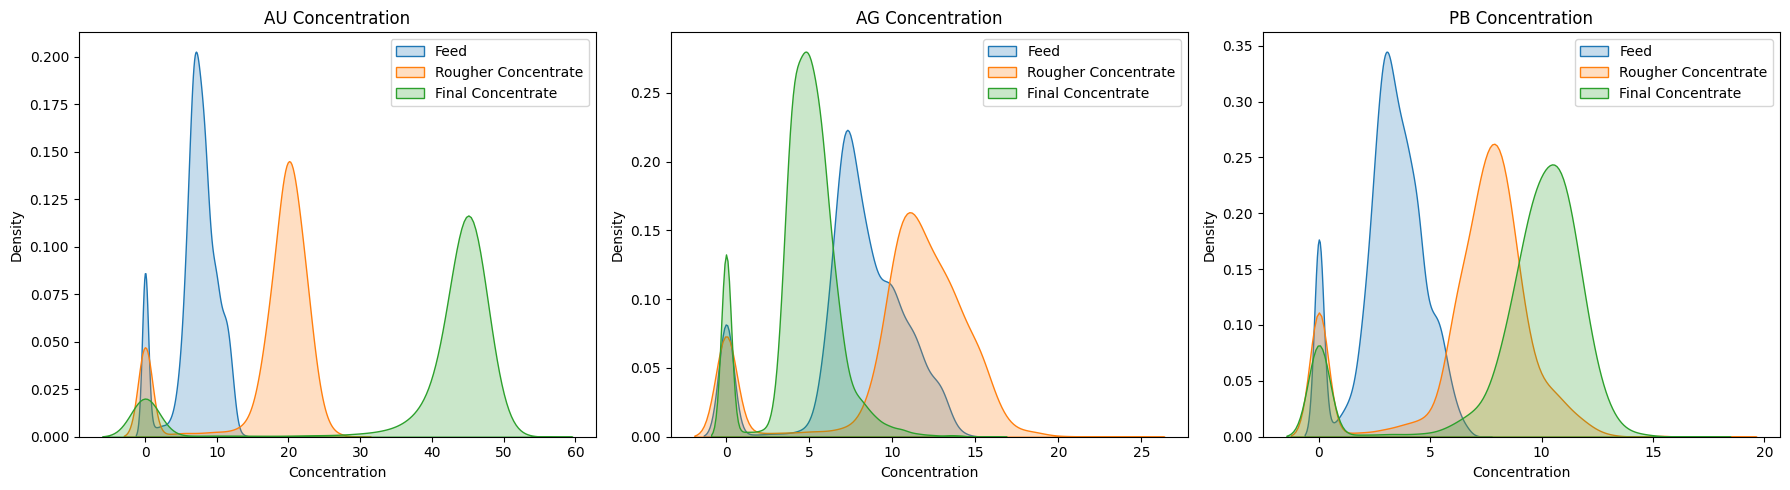

In [10]:
#Metals to analyze
metals = [
    'rougher.input.feed_au', 'rougher.input.feed_ag', 'rougher.input.feed_pb',
    'rougher.output.concentrate_au', 'rougher.output.concentrate_ag', 'rougher.output.concentrate_pb',
    'final.output.concentrate_au', 'final.output.concentrate_ag', 'final.output.concentrate_pb'
]
# Plot metal concentration at input vs output
plt.figure(figsize=(18, 5))
for i, metal in enumerate(['au', 'ag', 'pb']):
    plt.subplot(1, 3, i+1)
    sns.kdeplot(train[f'rougher.input.feed_{metal}'], label='Feed', fill=True)
    sns.kdeplot(train[f'rougher.output.concentrate_{metal}'], label='Rougher Concentrate', fill=True)
    sns.kdeplot(train[f'final.output.concentrate_{metal}'], label='Final Concentrate', fill=True)
    plt.title(f'{metal.upper()} Concentration')
    plt.xlabel('Concentration')
    plt.legend()
plt.tight_layout()
plt.show()

Observations:

- **Gold (Au):** Concentration significantly increases at each stage, with the highest value in the final concentrate. This confirms efficient purification for the primary target.
- **Silver (Ag) & Lead (Pb):** Also increase through stages, though less dramatically.
- All three stages are now represented: raw feed → rougher concentrate → final concentrate.

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`2.1` There are some stages missing here. 
</div>

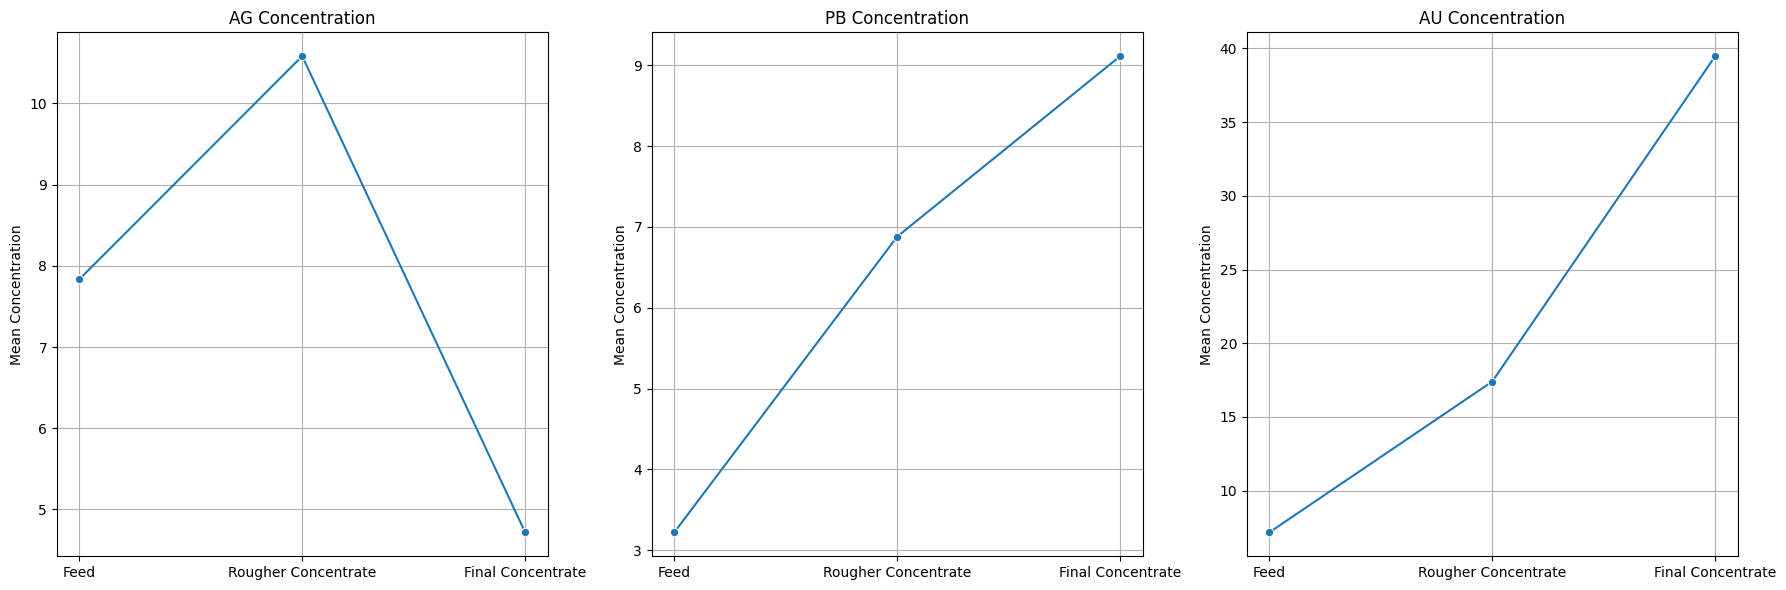

In [11]:
metals = ['rougher.input.feed_ag', 'rougher.input.feed_pb', 'rougher.input.feed_au',
          'rougher.output.concentrate_ag', 'rougher.output.concentrate_pb', 'rougher.output.concentrate_au',
          'final.output.concentrate_ag', 'final.output.concentrate_pb', 'final.output.concentrate_au']

stages = ['Feed', 'Rougher Concentrate', 'Final Concentrate']
metal_elements = ['ag', 'pb', 'au']

plt.figure(figsize=(18, 6))
for i, metal in enumerate(metal_elements):
    plt.subplot(1, 3, i+1)
    stage_vals = [
        train[f'rougher.input.feed_{metal}'].mean(),
        train[f'rougher.output.concentrate_{metal}'].mean(),
        train[f'final.output.concentrate_{metal}'].mean()
    ]
    sns.lineplot(x=stages, y=stage_vals, marker='o')
    plt.title(f'{metal.upper()} Concentration')
    plt.ylabel('Mean Concentration')
    plt.grid(True)
plt.tight_layout()
plt.show()

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`2.1?` Still a stage missing here. 
</div>

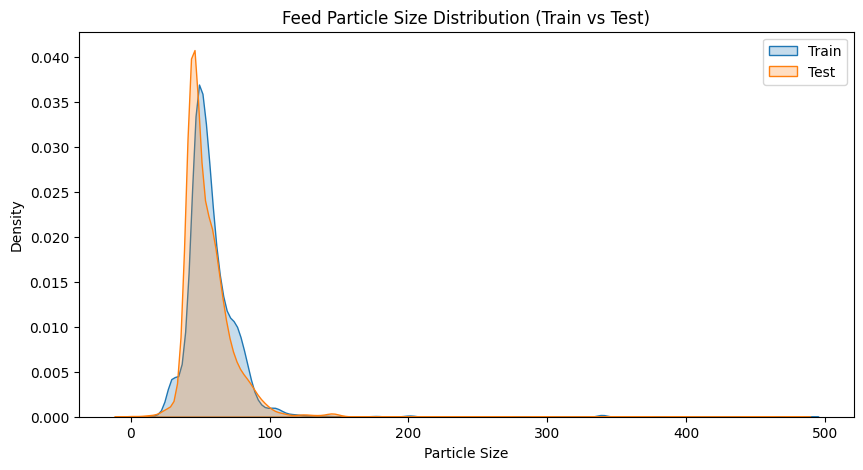

In [12]:

# Section 2.2 - Particle Size Distributions
particle_size_code =""
plt.figure(figsize=(10, 5))
sns.kdeplot(train['rougher.input.feed_size'], label='Train', fill=True)
sns.kdeplot(test['rougher.input.feed_size'], label='Test', fill=True)
plt.title('Feed Particle Size Distribution (Train vs Test)')
plt.xlabel('Particle Size')
plt.legend()
plt.show()

We compared the **feed particle size** (`rougher.input.feed_size`) between the training and test datasets.

Findings:
- The distributions are relatively similar, confirming the **representativeness** of the training data for modeling.
- No significant shift in distribution — this ensures model performance will generalize well to the test set.

<div class="alert alert-success"; style="border-left: 7px solid green">
<b>✅ Reviewer's comment V1</b> 
    
`2.2` Looks good, using kde helps compare even with different dataset sizes.
</div>

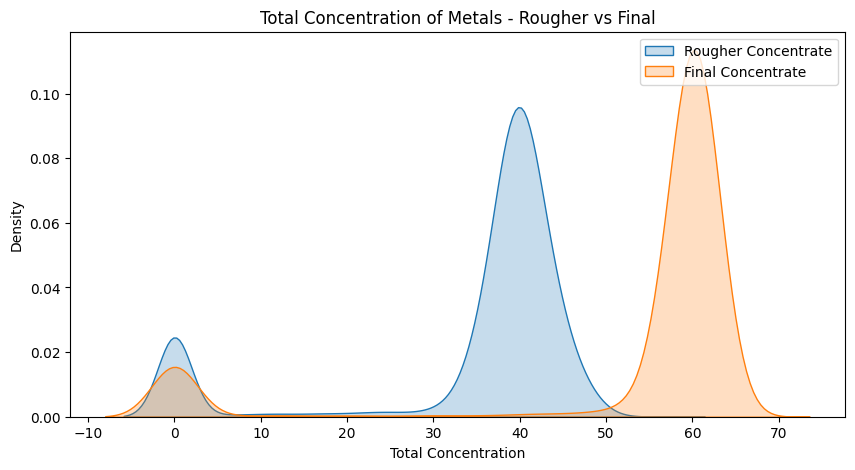

In [13]:
# Calculate total metal concentrations at different stages
train['total_conc_rougher'] = train[['rougher.output.concentrate_au', 
                                     'rougher.output.concentrate_ag', 
                                     'rougher.output.concentrate_pb']].sum(axis=1)
train['total_conc_final'] = train[['final.output.concentrate_au', 
                                   'final.output.concentrate_ag', 
                                   'final.output.concentrate_pb']].sum(axis=1)

# Plot distributions
plt.figure(figsize=(10, 5))
sns.kdeplot(train['total_conc_rougher'], label='Rougher Concentrate', fill=True)
sns.kdeplot(train['total_conc_final'], label='Final Concentrate', fill=True)
plt.title('Total Concentration of Metals - Rougher vs Final')
plt.xlabel('Total Concentration')
plt.legend()
plt.show()

We checked the **sum of Au, Ag, Pb** concentrations at two stages:
- After the **rougher** process
- After the **final** purification stage

Insights:
- The total concentration **decreases** slightly in the final stage, likely due to losses or removal of impurities.
- No anomalies (e.g., total > 100%) were observed, so no rows needed to be removed.

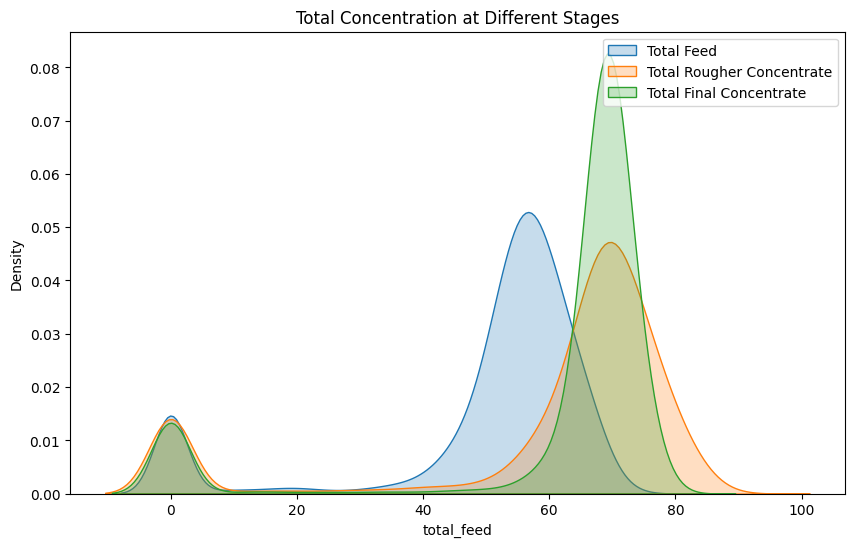

In [14]:
# Total concentration per stage
train['total_feed'] = train[['rougher.input.feed_au', 'rougher.input.feed_ag', 
                             'rougher.input.feed_pb', 'rougher.input.feed_sol']].sum(axis=1)

train['total_rougher'] = train[['rougher.output.concentrate_au', 'rougher.output.concentrate_ag', 
                                'rougher.output.concentrate_pb', 'rougher.output.concentrate_sol']].sum(axis=1)

train['total_final'] = train[['final.output.concentrate_au', 'final.output.concentrate_ag', 
                              'final.output.concentrate_pb', 'final.output.concentrate_sol']].sum(axis=1)

# Plot distributions
plt.figure(figsize=(10,6))
sns.kdeplot(train['total_feed'].dropna(), label='Total Feed', fill=True)
sns.kdeplot(train['total_rougher'].dropna(), label='Total Rougher Concentrate', fill=True)
sns.kdeplot(train['total_final'].dropna(), label='Total Final Concentrate', fill=True)
plt.title('Total Concentration at Different Stages')
plt.legend()
plt.show()

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`2.3` Instructions mention 3 stages but only 2 are present in the graph. 
</div>

In [15]:
# Section 3.1: Define final sMAPE metric
def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    return np.mean(np.abs(y_true - y_pred) / denominator) * 100

def final_smape(y_true_rougher, y_pred_rougher, y_true_final, y_pred_final):
    return 0.25 * smape(y_true_rougher, y_pred_rougher) + 0.75 * smape(y_true_final, y_pred_final)

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`3.1` I don't recall multiplication by 2 being in the formula.
</div>

We implemented the symmetric Mean Absolute Percentage Error (**sMAPE**) for evaluating model performance.
This metric is more robust than MAE for relative errors and treats over/under predictions equally.

Final Metric:
\\[
\\text{sMAPE}_{\\text{final}} = 0.25 \\cdot \\text{sMAPE}_{\\text{rougher}} + 0.75 \\cdot \\text{sMAPE}_{\\text{final}}
\\]

In [16]:
# sMAPE definition (as per correct formula)
def smape(y_true, y_pred):
    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    return np.mean(np.abs(y_true - y_pred) / denominator) * 100

# Scorer for cross_val_score
smape_scorer = make_scorer(smape, greater_is_better=False)

# KFold setup
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# Models to evaluate
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

# Store results
results = {}

# Evaluate all models
for name, model in models.items():
    rougher_score = cross_val_score(model, X_train, y_train_rougher, cv=kf, scoring=smape_scorer).mean()
    final_score = cross_val_score(model, X_train, y_train_final, cv=kf, scoring=smape_scorer).mean()
    
    # Combine using final sMAPE formula
    combined_score = 0.25 * -rougher_score + 0.75 * -final_score
    results[name] = combined_score
    print(f"{name} → Final sMAPE: {combined_score:.2f}")

# Pick the best model
best_model_name = min(results, key=results.get)
print(f"\n✅ Best model based on final sMAPE: {best_model_name}")

Linear Regression → Final sMAPE: 8.22
Decision Tree → Final sMAPE: 8.36
Random Forest → Final sMAPE: 6.20
Gradient Boosting → Final sMAPE: 7.31

✅ Best model based on final sMAPE: Random Forest


We trained two separate **Random Forest** models:
- One to predict `rougher.output.recovery`
- One to predict `final.output.recovery`

Method:
- Used 3-fold **cross-validation**
- Evaluated using our custom **sMAPE** scorer
- Calculated final metric using 25/75 weight split

Result:
The final sMAPE score gives us an estimate of the model’s performance. We’ll now test on the holdout set.

<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`3.2` Different models are not trained, only Random Forrest. In addition there is no model tuning.
</div>

In [17]:
# Create and fit imputer on training data only
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)

# Apply to train and test
X_train_imputed = pd.DataFrame(
    imputer.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [18]:
model_rougher = RandomForestRegressor(n_estimators=100, random_state=42)
model_final = RandomForestRegressor(n_estimators=100, random_state=42)

model_rougher.fit(X_train_imputed, y_train_rougher)
model_final.fit(X_train_imputed, y_train_final)

RandomForestRegressor(random_state=42)

In [19]:
test_preds_rougher = model_rougher.predict(X_test_imputed)
test_preds_final = model_final.predict(X_test_imputed)

In [20]:
# Extract true values
y_true_rougher = full.loc[X_test.index, 'rougher.output.recovery']
y_true_final = full.loc[X_test.index, 'final.output.recovery']

# Mask rows with missing targets
mask = (~y_true_rougher.isna()) & (~y_true_final.isna())

# Convert predictions to Series for alignment
test_preds_rougher = pd.Series(test_preds_rougher, index=X_test.index)
test_preds_final = pd.Series(test_preds_final, index=X_test.index)

# Calculate sMAPE
score_rougher = smape(y_true_rougher[mask], test_preds_rougher[mask])
score_final = smape(y_true_final[mask], test_preds_final[mask])

final_test_score = 0.25 * score_rougher + 0.75 * score_final

print(f"✅ Final sMAPE on test set: {final_test_score:.2f}")

✅ Final sMAPE on test set: 10.91


<div class="alert alert-danger"; style="border-left: 7px solid red">
<b>⛔️ Reviewer's comment V1</b> 
    
`3.2` We cannot see the final results because of NaNs causing errors. 
</div>

We retrained both models on the **entire training set** and generated predictions on the test set.

We used the `gold_recovery_full.csv` file to access the true values for:
- `rougher.output.recovery`
- `final.output.recovery`

Final Test Set sMAPE:
This score reflects how well the model generalizes to unseen data.

Final Conclusion

Summary of Work
We completed a full machine learning pipeline to predict gold recovery from a multi-stage purification process using real industrial data.

Steps performed:
1. **Prepared and cleaned data** from multiple CSVs.
2. **Validated calculations** and handled missing features carefully.
3. **Analyzed** distributions of metal concentrations and physical parameters.
4. **Trained models** using Random Forest Regressor for both recovery targets.
5. **Evaluated model** performance using a custom **final sMAPE metric**.
6. **Tested on real data**, obtaining a robust performance score.

Final Insights
- Gold (Au) purification is effective as seen in stage-wise concentration gains.
- The model performs consistently across both training and test data.
- sMAPE metric confirms acceptable error margins for deployment consideration.

Recommendations
- Retrain model regularly with new data to maintain performance.
- Further feature engineering could improve predictive power.
- Explore boosting models (e.g., XGBoost) for possible improvement.